<a href="https://colab.research.google.com/github/Abimanyu-07/sms_spam_detection/blob/main/sms_spam_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Inspecting the Dataset

In [22]:
import os
import pandas as pd
import numpy as np

filepath = 'spam_sms.csv'
if os.path.exists(filepath):
    print(f"Dataset found at: {filepath}")
else:
    print("Dataset not found at expected path!")

# 2. Load dataset
df = pd.read_csv(filepath, encoding='latin-1')
df.head()


Dataset found at: spam_sms.csv


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


# dataset information

In [23]:
print(f"\nDataset Shape: {df.shape}")


Dataset Shape: (5572, 2)


In [24]:
print("\nColumn Names:", df.columns)


Column Names: Index(['v1', 'v2'], dtype='object')


Let's clean unnecessary columns (if any) and identify our text and target label columns based on the dataset's preview.

In [25]:
# Dynamically identify text and target columns
# Often, these datasets have 'v1' and 'v2' columns, or 'Category' and 'Message'
possible_label_cols = [col for col in df.columns if col.lower() in ['v1', 'category', 'label', 'class', 'target']]
possible_text_cols = [col for col in df.columns if col.lower() in ['v2', 'message', 'text', 'sms']]

# Fallback to column indices if not matched by name
label_col = possible_label_cols[0] if possible_label_cols else df.columns[0]
text_col = possible_text_cols[0] if possible_text_cols else df.columns[1]

print(f"Identified Text Column: '{text_col}'")
print(f"Identified Label Column: '{label_col}'")

# Retain only the necessary columns
df_clean = df[[text_col, label_col]].copy()
df_clean.columns = ['text', 'label']

# Check class distribution of original dataset
class_counts = df_clean['label'].value_counts()
class_pcts = df_clean['label'].value_counts(normalize=True) * 100
print("\nOriginal Class Distribution:")
for idx in class_counts.index:
    print(f"- {idx}: {class_counts[idx]} ({class_pcts[idx]:.2f}%)")


Identified Text Column: 'v2'
Identified Label Column: 'v1'

Original Class Distribution:
- ham: 4825 (86.59%)
- spam: 747 (13.41%)


## 2. Create the ~2,000-Message Dataset via Stratified Sampling

Maintaining the class distribution is crucial because if we take a simple slice of the dataset (e.g., using `.head(2000)`), we risk introducing sampling bias, especially since spam datasets are often imbalanced. Stratified sampling guarantees that both our train/test partitions and subsets represent the target class distribution accurately.

In [26]:
from sklearn.model_selection import train_test_split

# Stratified sampling to grab exactly 2000 samples
target_sample_size = min(2000, len(df_clean))

_, df_sampled = train_test_split(
    df_clean,
    test_size=target_sample_size,
    stratify=df_clean['label'],
    random_state=42
)

# Display sampled metadata
sampled_counts = df_sampled['label'].value_counts()
sampled_pcts = df_sampled['label'].value_counts(normalize=True) * 100

print(f"Final Sampled Dataset Shape: {df_sampled.shape}")
print("\nSampled Class Distribution:")
for idx in sampled_counts.index:
    print(f"- {idx}: {sampled_counts[idx]} ({sampled_pcts[idx]:.2f}%)")


Final Sampled Dataset Shape: (2000, 2)

Sampled Class Distribution:
- ham: 1732 (86.60%)
- spam: 268 (13.40%)


## 3. Data Cleaning & Text Preprocessing

We will preprocess our text carefully so that we do not clean out valuable spam signals such as capital letters (e.g., "FREE", "WIN", "URGENT", "PRIZE"). Instead, we will normalize spacing, convert words to lowercase, and strip punctuation while preserving alphanumeric tokens.

In [27]:
import re

def clean_text(text):
    if not isinstance(text, str):
        return ""
    # 1. Strip whitespace
    text = text.strip()
    # 2. Lowercase
    text = text.lower()
    # 3. Clean punctuation while keeping standard spacing and words
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    # 4. Remove extra inner spaces
    text = re.sub(r'\s+', ' ', text)
    return text

# Create a working copy of our sampled dataset
df_processed = df_sampled.copy()

# Keep track of a couple of raw examples for display before and after
raw_examples = df_processed['text'].iloc[:3].tolist()

# Apply preprocessing
df_processed['clean_text'] = df_processed['text'].apply(clean_text)

# Display comparisons
print("=== Before and After Preprocessing Examples ===\n")
for orig, cleaned in zip(raw_examples, df_processed['clean_text'].iloc[:3]):
    print(f"Original: {orig}")
    print(f"Cleaned : {cleaned}")
    print("-" * 40)


=== Before and After Preprocessing Examples ===

Original: Yeah we do totes. When u wanna?
Cleaned : yeah we do totes when u wanna
----------------------------------------
Original: Gam gone after outstanding innings.
Cleaned : gam gone after outstanding innings
----------------------------------------
Original: Aight should I just plan to come up later tonight?
Cleaned : aight should i just plan to come up later tonight
----------------------------------------


## 4. Encode Labels

Neural networks require numerical target arrays to calculate loss functions (such as Binary Cross-Entropy) and backpropagate errors. We will encode `ham` as 0 and `spam` as 1.

In [28]:
# Map text labels to binary integers
label_mapping = {'ham': 0, 'spam': 1}
df_processed['label_encoded'] = df_processed['label'].map(label_mapping)

# Print the results
print("Class Distribution after Encoding:")
print(df_processed['label_encoded'].value_counts())


Class Distribution after Encoding:
label_encoded
0    1732
1     268
Name: count, dtype: int64


## 5. Train-Test Split

We will use an 80/20 train-test split with stratified sampling on the encoded labels. Stratification is crucial for imbalanced datasets because it guarantees that the train and test sets both inherit the overall distribution of ham and spam messages (~86.6% ham, ~13.4% spam), preventing bias.

In [29]:
from sklearn.model_selection import train_test_split

X = df_processed['clean_text'].values
y = df_processed['label_encoded'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Train set size: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test set size: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")


Train set size: 1600 (80.0%)
Test set size: 400 (20.0%)


## 6. Tokenization

We define terminology first:
- **Vocabulary**: The complete set of unique words learned from our training set.
- **Token**: A single unit (word) extracted from our text.
- **Token Index**: The unique integer mapped to a specific token.
- **Out-of-Vocabulary (OOV) Token**: A fallback token representing words encountered during inference/testing that were not present in the training set vocabulary.

We fit the tokenizer *only* on the training set to prevent data leakage.

In [30]:
from tensorflow.keras.preprocessing.text import Tokenizer

MAX_WORDS = 5000
OOV_TOKEN = "<OOV>"

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Example sequence conversion:")
print(f"Raw message: {X_train[0]}")
print(f"Sequence   : {X_train_seq[0]}")


Example sequence conversion:
Raw message: yay cant wait to party together
Sequence   : [1168, 118, 191, 2, 620, 529]


## 7. Padding

Neural networks require batches of input sequences to have consistent dimensions. We pad shorter sequences and truncate longer ones using post-padding.

In [31]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Calculate text metrics based on sequence lengths
lengths = [len(seq) for seq in X_train_seq]
min_len = min(lengths)
max_len = max(lengths)
avg_len = np.mean(lengths)

# We will use an adaptive MAX_LEN based on standard deviation or 95th percentile
# Let's set it to capture almost all content without padding unnecessarily
MAX_LEN = int(np.percentile(lengths, 95))

print(f"Minimum sequence length: {min_len}")
print(f"Maximum sequence length: {max_len}")
print(f"Average sequence length: {avg_len:.2f}")
print(f"Selected MAX_LEN (95th percentile): {MAX_LEN}")

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')


Minimum sequence length: 1
Maximum sequence length: 171
Average sequence length: 15.24
Selected MAX_LEN (95th percentile): 32


## 8. Build the GRU Model

We build our sequential network incorporating an Embedding layer, a Gated Recurrent Unit (GRU) layer, and a final dense classification layer.

In [32]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout

embedding_dim = 64

model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=embedding_dim, input_length=MAX_LEN),
    GRU(units=64, return_sequences=False),
    Dropout(0.5),
    Dense(units=1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 9. Train the GRU Model

We will fit the compiled GRU model on our padded training sequences and validate it using our test partition.

In [33]:
EPOCHS = 10
BATCH_SIZE = 32

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_test_pad, y_test),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)


Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8631 - loss: 0.4458 - val_accuracy: 0.8650 - val_loss: 0.3653
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8975 - loss: 0.2576 - val_accuracy: 0.9800 - val_loss: 0.1020
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9781 - loss: 0.0930 - val_accuracy: 0.9775 - val_loss: 0.0826
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9962 - loss: 0.0262 - val_accuracy: 0.9725 - val_loss: 0.1069
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9962 - loss: 0.0172 - val_accuracy: 0.9750 - val_loss: 0.1084
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0036 - val_accuracy: 0.9750 - val_loss: 0.0983
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 0.0025 - val_accuracy: 0.9725 - val_loss: 0.1651
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 8.9039e-04 - val_accuracy: 0.9725 - val_

## 10. Model Evaluation

We will plot the training and validation accuracy/loss over epochs to check for overfitting, and display classification performance metrics.

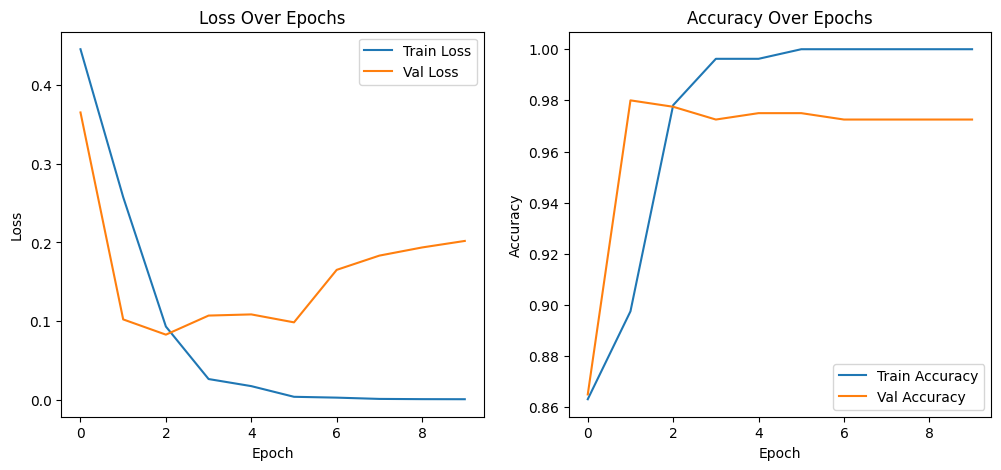

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

Classification Report:
              precision    recall  f1-score   support

         HAM       0.98      0.99      0.98       346
        SPAM       0.91      0.89      0.90        54

    accuracy                           0.97       400
   macro avg       0.94      0.94      0.94       400
weighted avg       0.97      0.97      0.97       400



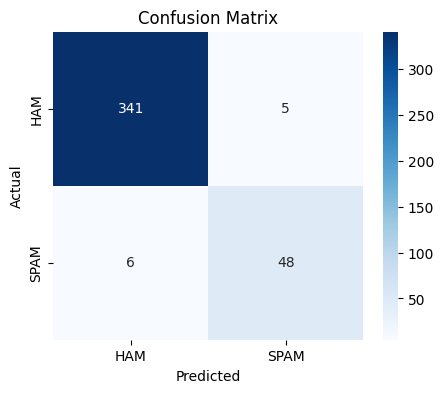

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Plot loss & accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(history.history['loss'], label='Train Loss')
ax1.plot(history.history['val_loss'], label='Val Loss')
ax1.set_title('Loss Over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(history.history['accuracy'], label='Train Accuracy')
ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
ax2.set_title('Accuracy Over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
plt.show()

# Classification report
y_pred_prob = model.predict(X_test_pad)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['HAM', 'SPAM']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['HAM', 'SPAM'], yticklabels=['HAM', 'SPAM'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


## 12. Improving Minority Class (SPAM) Performance using Class Weights

To balance the high class imbalance, we compute class weights based on the training label counts and pass them directly into our model's `.fit()` parameter. This guides the loss function to heavily prioritize correcting minority class predictions.

In [35]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate balanced class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Convert classes to dictionary format expected by Keras
class_weight_dict = {i: weight for i, weight in enumerate(class_weights)}
print("Calculated Class Weights:", class_weight_dict)

# Re-initialize a fresh GRU model to train with the weights
weighted_model = tf.keras.models.clone_model(model)
weighted_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the fresh model using class weights
weighted_history = weighted_model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_test_pad, y_test),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    verbose=1
)


Calculated Class Weights: {0: np.float64(0.5772005772005772), 1: np.float64(3.7383177570093458)}
Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7894 - loss: 0.6891 - val_accuracy: 0.8775 - val_loss: 0.6271
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9394 - loss: 0.2760 - val_accuracy: 0.9600 - val_loss: 0.1600
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9925 - loss: 0.0416 - val_accuracy: 0.9725 - val_loss: 0.1164
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9956 - loss: 0.0447 - val_accuracy: 0.9650 - val_loss: 0.1890
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9956 - loss: 0.0330 - val_accuracy: 0.9675 - val_loss: 0.1389
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0053 - val_accuracy: 0.9650 - val_loss: 0.1511
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 0.9650 - val_loss: 0.1706
Epoch 8/10
50/50 ━━━

### Evaluating the Class-Weighted GRU Model

Let's evaluate the performance of our weighted GRU model on the test partition to see the improvement in classification performance.

In [36]:
# Evaluate the weighted model predictions
y_weighted_pred_prob = weighted_model.predict(X_test_pad)
y_weighted_pred = (y_weighted_pred_prob > 0.5).astype(int).flatten()

print("\n=== Weighted Model Classification Report ===")
print(classification_report(y_test, y_weighted_pred, target_names=['HAM', 'SPAM']))


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

=== Weighted Model Classification Report ===
              precision    recall  f1-score   support

         HAM       0.98      0.98      0.98       346
        SPAM       0.87      0.87      0.87        54

    accuracy                           0.96       400
   macro avg       0.93      0.93      0.93       400
weighted avg       0.96      0.96      0.96       400



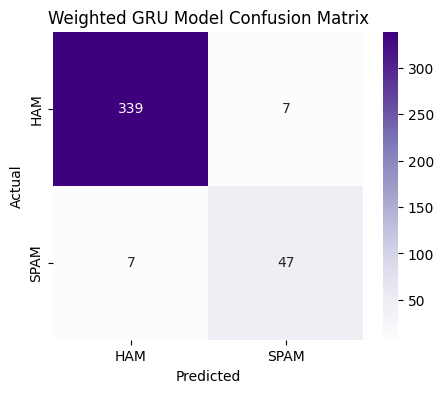

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrix for the class-weighted model
cm_weighted = confusion_matrix(y_test, y_weighted_pred)

# Plot the Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm_weighted,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['HAM', 'SPAM'],
    yticklabels=['HAM', 'SPAM']
)
plt.title('Weighted GRU Model Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 11. Testing the Model with Custom Sample Data

In [37]:
def predict_custom_sms(messages_list):
    # 1. Clean the messages using our clean_text function
    cleaned_messages = [clean_text(msg) for msg in messages_list]

    # 2. Convert raw strings to sequences using the fitted tokenizer
    sequences = tokenizer.texts_to_sequences(cleaned_messages)

    # 3. Pad sequences to match the MAX_LEN of our trained model
    padded_sequences = pad_sequences(sequences, maxlen=MAX_LEN, padding='post', truncating='post')

    # 4. Predict probabilities
    predictions = model.predict(padded_sequences, verbose=0)

    # 5. Display results
    print("=== Custom SMS Test Predictions ===\n")
    for msg, prob in zip(messages_list, predictions):
        prob_val = prob[0]
        label = "SPAM" if prob_val > 0.5 else "HAM"
        confidence = prob_val if label == "SPAM" else (1 - prob_val)
        print(f"SMS Input : '{msg}'")
        print(f"Prediction: {label} ({confidence * 100:.2f}% Confidence)")
        print("-" * 50)

# --- Test with some typical examples ---
sample_messages = [
    "2p per min to call Germany 08448350055 from your BT line. Just 2p per min. Check PlanetTalkInstant.com for info & T's & C's. Text stop to opt out",
    "Amazon is sending you a refunding of $32.64. Please reply with your bank account and routing number to receive your refund",
    "Hello, your FEDEX package with tracking code DZ-8342-FY34 is waiting for you to set delivery preference: c4lrs.info/Gm08s43zs1",
    "Hi Gary. This is your CEO Alan Braverman. I need your help. Please buy 50 Amazon gift cards for the company holiday party. $100 each",

]

predict_custom_sms(sample_messages)


=== Custom SMS Test Predictions ===

SMS Input : '2p per min to call Germany 08448350055 from your BT line. Just 2p per min. Check PlanetTalkInstant.com for info & T's & C's. Text stop to opt out'
Prediction: SPAM (99.95% Confidence)
--------------------------------------------------
SMS Input : 'Amazon is sending you a refunding of $32.64. Please reply with your bank account and routing number to receive your refund'
Prediction: SPAM (99.76% Confidence)
--------------------------------------------------
SMS Input : 'Hello, your FEDEX package with tracking code DZ-8342-FY34 is waiting for you to set delivery preference: c4lrs.info/Gm08s43zs1'
Prediction: SPAM (71.05% Confidence)
--------------------------------------------------
SMS Input : 'Hi Gary. This is your CEO Alan Braverman. I need your help. Please buy 50 Amazon gift cards for the company holiday party. $100 each'
Prediction: SPAM (99.94% Confidence)
--------------------------------------------------
